# Modelling, Hyperparameter Tuning and Evaluation

## Step 0: Environment Setup

### 0.1 Library Imports, Dataset Directory and Other Configurations

In [45]:
# Library imports
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
)
from sklearn.calibration import calibration_curve

# Seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

# Warnings filter
warnings.filterwarnings("ignore", category=UserWarning)

# Directory
PROCESSED = Path("..") / "data" / "processed"
xtr       = np.load(PROCESSED / "train_sub70000_x.npy", mmap_mode="r")
ytr       = np.load(PROCESSED / "train_sub70000_y.npy").astype(np.float32).reshape(-1)
xva       = np.load(PROCESSED / "valid_full_x.npy", mmap_mode="r")
yva       = np.load(PROCESSED / "valid_full_y.npy").astype(np.float32).reshape(-1)
stats     = np.load(PROCESSED / "channel_stats.npz")
mean_t    = torch.tensor(stats["mean"], dtype=torch.float32, device=DEVICE)
std_t     = torch.tensor(stats["std"], dtype=torch.float32, device=DEVICE)

### 0.2 Preprocessing Functions

In [7]:
# Stain color matrix from Ruifrok & Johnston (2001)
STAIN_COLOURS = torch.tensor([
    [0.65, 0.70, 0.29],
    [0.07, 0.99, 0.11],
    [0.27, 0.57, 0.78],
], dtype=torch.float32)
DECONVOLUTION = torch.linalg.inv(STAIN_COLOURS)

# Convert pixel values to the range of [0, 1]
def to_float(x):
    return x.float() / 255.0 if x.dtype == torch.uint8 else x

# Separate image to layers
def rgb_to_hed(x):
    density = -torch.log(x.clamp_min(1e-6))
    return torch.einsum("nchw,cd->ndhw", density, DECONVOLUTION.to(x.device))

# Combine layers into image
def hed_to_rgb(stains):
    density = torch.einsum("nchw,cd->ndhw", stains, STAIN_COLOURS.to(stains.device))
    return torch.exp(-density).clamp(0, 1)

# Flipping and rotation
def d4_dihedral(x):
    for transform in (lambda t: t.transpose(-2, -1),
                      lambda t: t.flip(-2),
                      lambda t: t.flip(-1)):
        coin = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5
        x = torch.where(coin, transform(x), x)
    return x

# Modify the intensity of stains
def he_stain_jitter(x, strength=0.05):
    if strength <= 0:
        return x
    stains = rgb_to_hed(x)
    shape = (len(x), 2, 1, 1)
    scale = 1 + (torch.rand(shape, device=x.device) * 2 - 1) * strength
    shift = (torch.rand(shape, device=x.device) * 2 - 1) * strength
    return hed_to_rgb(torch.cat([stains[:, :2] * scale + shift, stains[:, 2:]], dim=1))

# Alter picture-related settings
def photometric_jitter(x, strength=0.15):
    if strength <= 0:
        return x
    factors = 1 + (torch.rand(3, len(x), 1, 1, 1, device=x.device) * 2 - 1) * strength
    brightness, contrast, saturation = factors
    x = x * brightness
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
    return (x - gray) * saturation + gray

# Crop patches to the central region (32 x 32 for PCam)
def centre_crop(x, size):
    h = x.shape[-2]
    if size >= h:
        return x
    off = (h - size) // 2
    return x[..., off:off + size, off:off + size]

# z-score normalization
def normalise(x, mean, std):
    return ((x - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)).contiguous()

## Step 1: Model Architecture

### 1.1 Architecture of CNN

In [8]:
class BaselineCNN(nn.Module):

    # Declares the components inside the model: head, features and classifier
    def __init__(self,
                 widths=(32, 64, 128, 256),     # Number of 3x3 filters
                 dropout=0.3,                   # Random zeroing on dense head during training
                 block_dropout=0.05,            # Random zeroing on feature map during training
                 head="gap",                    # Determines where the decision is read from (gap, center, both)
                 fc_dim=128):                   # Size of dense layer (hidden layers)

        # Initialize the neural network module in PyTorch
        super().__init__()

        # Construct the head used by NN later
        self.head = head

        # The layers involved in the baseline CNN, with 3 channels in the beginning
        layers, prev = [], 3

        # Loop through each filter block
        for w in widths:
            layers += [nn.Conv2d(prev, w, 3, padding=1, bias=False),    # prev = channels, w = number of 3x3 filters & output count
                       nn.BatchNorm2d(w),                               # Perform normalization on the outputs
                       nn.ReLU(inplace=True),                           # Use ReLU to remove negative values
                       nn.Conv2d(w, w, 3, padding=1, bias=False),       # Perform convolution again to learn extra information from adjacent
                       nn.BatchNorm2d(w),                               # Perform normalization again
                       nn.ReLU(inplace=True),                           # Remove negative values again
                       nn.MaxPool2d(2),                                 # Use a 2x2 filter to retain the max value
                       nn.Dropout2d(block_dropout)]                     # Ignore 5% of outputs to avoid overreliance on a specific pattern
            prev = w                                                    # Once done, update the current channel number

        # Convert the layers into steps (these are the hidden layers)
        self.features = nn.Sequential(*layers)

        # Classifier to determine the prediction
        self.classifier = nn.Sequential(
            nn.Linear(prev * (2 if head == "both" else 1), fc_dim),     # Combine the channels into fc_dim
            nn.BatchNorm1d(fc_dim),                                     # Normalize output
            nn.ReLU(inplace=True),                                      # Remove negative values
            nn.Dropout(dropout),                                        # Ignore 30% of features
            nn.Linear(fc_dim, 1),                                       # Convert the final hidden layer into a result
        )

    # Defines the flow of the model
    def forward(self, x):

        # Run inputs over the layers
        f = self.features(x)

        # Once done, get the average by combining each value in each channel (for "gap")
        gap = f.mean(dim=(-2, -1))

        # Once done, get the average by combining only on the center region (for "center")
        centre = f[..., 2:4, 2:4].mean(dim=(-2, -1))

        # Determine which one goes into the classifier, if "both" then combine both values from gap and center
        z = gap if self.head == "gap" else centre if self.head == "centre" else \
            torch.cat([gap, centre], dim=1)

        # Return the final prediction
        return self.classifier(z).squeeze(-1)

### 1.2 Architecture of CNN-BiLSTM

In [9]:
# The class that handles the additive attention mechanism
class AttentionPool(nn.Module):

    # Declare the components inside the attention mechanism
    def __init__(self, dim, hidden=128):
        super().__init__()

        # The attention score, calculated with a tiny network
        self.score = nn.Sequential(nn.Linear(dim, hidden),      # Combine into 128 features
                                   nn.Tanh(),                   # Use tanh: range [-1, 1]
                                   nn.Linear(hidden, 1))        # Combine into one output

    # Define how does the attention mechanism work
    def forward(self, h):

        # Calculate the attention score and convert them into fractions that add to 1
        w = torch.softmax(self.score(h), dim=1)

        # Return the weighted average for the image, and the original weights for each element
        return (w * h).sum(dim=1), w.squeeze(-1)


# The class that handles the CNN-BiLSTM model
class CNNBiLSTM(nn.Module):

    # Define the components inside the model
    def __init__(self,
                 widths=(32, 64, 128, 256),     # Number of filters for each block
                 grid=6,                        # Size of map before feeding into LSTM
                 hidden=256,                    # Size of LSTM memory
                 num_layers=1,                  # Number of LSTM layers
                 dropout=0.3,                   # Percentage of features to ignore in LSTM (if stacked) and classifier
                 block_dropout=0.05,            # Percentage of features to ignore in conv blocks
                 fc_dim=128,                    # Size of the dense layer (hidden layers)
                 head="attn"):                  # How the final decision is made (attn, center, both)

        # Constructors and declaration of local variables
        super().__init__()
        self.head = head
        self.grid = grid

        # Create layers based on the filter block
        layers, prev = [], 3
        for w in widths:
            layers += [nn.Conv2d(prev, w, 3, padding=1, bias=False),    # prev = channel, w = number of filters & output channel count
                       nn.BatchNorm2d(w),                               # Normalization on result
                       nn.ReLU(inplace=True),                           # Remove negative values
                       nn.Conv2d(w, w, 3, padding=1, bias=False),       # Additional conv layer to learn more about image
                       nn.BatchNorm2d(w),                               # Normalization
                       nn.ReLU(inplace=True),                           # Remove negative values
                       nn.MaxPool2d(2),                                 # Max pooling on 2x2 window
                       nn.Dropout2d(block_dropout)]                     # Ignore 5% of the features
            prev = w

        # Add the layers to features
        self.features = nn.Sequential(*layers)

        # A pool to reduce the layer size to cater for LSTM
        self.pool = nn.AdaptiveAvgPool2d((grid, grid))

        # The LSTM component
        self.rnn = nn.LSTM(input_size=prev,                                 # The input size
                           hidden_size=hidden,                              # The size of features in LSTM layers
                           num_layers=num_layers,                           # Number of LSTM layers
                           batch_first=True,                                # Data shape becomes (batch, step/pixel, feature)
                           bidirectional=True,                              # Two-way processing
                           dropout=dropout if num_layers > 1 else 0.0,      # Only apply dropout if more than one LSTM layer
        )

        # The attention component
        self.attn = (AttentionPool(2 * hidden, hidden=fc_dim)
                     if head in ("attn", "both") else None)

        # The classifier
        self.classifier = nn.Sequential(
            nn.Linear(2 * hidden * (2 if head == "both" else 1), fc_dim),   # Convert layer output to fc_dim
            nn.BatchNorm1d(fc_dim),                                         # Normalization
            nn.ReLU(inplace=True),                                          # ReLU to remove negative values
            nn.Dropout(dropout),                                            # Ignore 30% of the features
            nn.Linear(fc_dim, 1),                                           # Output a logit to be converted later
        )

    # Define the flow of the model
    def forward(self, x, return_attention=False):

        # Run the convolutional layers and aggregate / pool output to the intended size
        f = self.pool(self.features(x))

        # Rearrange the outputs for LSTM
        b, c, g, _ = f.shape
        seq = f.permute(0, 2, 3, 1).reshape(b, g * g, c)

        # Run the LSTM component
        h, _ = self.rnn(seq)

        # Run the attention component
        attn = None
        if self.head in ("attn", "both"):
            ctx, attn = self.attn(h)
            attn = attn.view(b, g, g)

        # If the center region is involved, reshape the weights and take the middle region
        if self.head in ("centre", "both"):
            m = g // 2
            centre = h.view(b, g, g, -1)[:, m - 1:m + 1, m - 1:m + 1].mean(dim=(1, 2))

        # Determine the output to be passed to the classifier
        z = (ctx if self.head == "attn" else
             centre if self.head == "centre" else
             torch.cat([ctx, centre], dim=1))

        # Run the classifier
        logits = self.classifier(z).squeeze(-1)

        # Return the results
        return (logits, attn) if return_attention else logits

### 1.3 Baseline Model Training

#### 1.3.1 Training Configuration

##### Predict function

In [10]:
@torch.no_grad()
def predict(model, images, labels, *, batch_size=512, input_size=96):
    model = model.to(DEVICE).eval()                                                     # Switch to evaluation mode (no dropout)
    out_probs = []
    for start in range(0, len(labels), batch_size):                                     # Loop through each batch
        xb = torch.from_numpy(np.ascontiguousarray(images[start:start + batch_size]))   # Retrieve image data
        xb = to_float(xb.permute(0, 3, 1, 2).contiguous().to(DEVICE))                   # Perform reshape
        xv = normalise(centre_crop(xb, input_size), mean_t, std_t)                      # Perform normalization
        out = model(xv)                                                                 # Fit the model for prediction
        out = out[0] if isinstance(out, tuple) else out                                 # Only take the logits
        out_probs.append(torch.sigmoid(out.float()).cpu().numpy())                      # Apply sigmoid to convert to probabilities
    return np.concatenate(out_probs), np.asarray(labels, dtype=np.float32)              # Record and return outputs

##### Metric function

In [11]:
def metrics(probs, targets, threshold=0.5):
    y = np.asarray(targets).astype(int)                                                 # Retrieve labels
    p = np.clip(np.asarray(probs, dtype=np.float64), 1e-7, 1 - 1e-7)                    # Cap probabilities to avoid errors
    pred = (p >= threshold).astype(int)                                                 # Convert probabilities into predictions
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()                   # Calculate the confusion matrix
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)                             # Calculate TPR and TNR

    # Return all metrics here
    return {
        "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float((sens + spec) / 2),
        "auc": float(roc_auc_score(y, p)),
        "average_precision": float(average_precision_score(y, p)),
        "f1": float(f1_score(y, pred)),
        "mcc": float(matthews_corrcoef(y, pred)),
        "sensitivity": float(sens), "specificity": float(spec),
        "precision": float(tp / max(tp + fp, 1)),
        "nll": float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()),
        "brier": float(brier_score_loss(y, p)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "n": int(len(y)),
    }

##### Train function

In [12]:
# The function to train model
def train(model, name, train_data, val_data, *, epochs=30, batch_size=256, lr=3e-4,
          weight_decay=1e-4, label_smoothing=0.05, aug_hed_sigma=0.05,
          aug_photometric=0.15, input_size=96, seed=42, verbose=True):

    # Define seed for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # The device (GPU/CPU) to train the model
    model = model.to(DEVICE)

    # Get the training and validation data
    x_train, y_train = train_data
    x_val, y_val = val_data

    # Determine the number of batches (size must be same for BatchNorm)
    steps_per_epoch = len(y_train) // batch_size

    # Optimizer used is AdamW, and loss function used is logit
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()

    # Details to record throughout training
    history = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_loss",
                               "val_acc", "val_auc", "seconds")}
    best = {"epoch": -1, "val_auc": -np.inf, "val_acc": 0.0, "val_nll": np.inf}
    best_state = None
    rng = np.random.default_rng(seed)

    # Loop through each epoch
    for epoch in range(1, epochs + 1):

        # Begin model training
        t0 = time.time()
        model.train()
        run_loss, run_correct, run_n = 0.0, 0, 0

        # Loop through each batch in epoch
        order = rng.permutation(len(y_train))
        for start in range(0, steps_per_epoch * batch_size, batch_size):

            # Retrieve the images
            sel = np.sort(order[start:start + batch_size])                          # Sorting makes processing faster
            xb = torch.from_numpy(np.ascontiguousarray(x_train[sel]))               # Load image data
            xb = xb.permute(0, 3, 1, 2).contiguous().to(DEVICE)                     # Reshape to correct shape
            yb = torch.from_numpy(y_train[sel]).to(DEVICE)                          # Extract the labels

            # Preprocessing on image
            x = d4_dihedral(to_float(xb))                                           # Flips and rotations
            x = he_stain_jitter(x, strength=aug_hed_sigma)                          # Stain-colour jitter
            x = photometric_jitter(x, strength=aug_photometric)                     # Brightness / contrast
            x = normalise(centre_crop(x.clamp(0, 1), input_size), mean_t, std_t)    # Normalization
            target = yb * (1 - label_smoothing) + 0.5 * label_smoothing             # Label smoothing: Better calibration

            # Optimizer (controls learning rate)
            optimizer.zero_grad(set_to_none=True)                                   # Clear old gradients
            out = model(x)                                                          # Forward pass
            loss = criterion(out, target)                                           # Compute loss
            loss.backward()                                                         # Backpropagate
            optimizer.step()                                                        # Update weights

            # Record loss (for reporting)
            run_loss += loss.item() * len(sel)                                      # Calculate total loss (loss.item() is average)
            run_correct += ((out.detach() >= 0).float() == yb).sum().item()         # Count the number of correct predictions
            run_n += len(sel)                                                       # Record the number of images seen

        # Training done. Proceed with validation
        val_probs, _ = predict(model, x_val, y_val, input_size=input_size)          # Fit model into validation set
        m = metrics(val_probs, y_val)                                               # Retrieve the metrics

        # Record the epoch detail
        for key, value in (("epoch", epoch), ("train_loss", run_loss / run_n),
                           ("train_acc", run_correct / run_n), ("val_loss", m["nll"]),
                           ("val_acc", m["accuracy"]), ("val_auc", m["auc"]),
                           ("seconds", time.time() - t0)):
            history[key].append(value)

        # If AUC improved, record the details of the best configuration
        if m["auc"] > best["val_auc"]:
            best = {"epoch": epoch, "val_auc": m["auc"], "val_acc": m["accuracy"],
                    "val_nll": m["nll"]}
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        # Print details if verbose is turned on
        if verbose:
            print(f"    ep {epoch:>3}/{epochs}  loss {run_loss / run_n:.4f} "
                  f"acc {run_correct / run_n:.4f} | val acc {m['accuracy']:.4f} "
                  f"auc {m['auc']:.4f}  {time.time() - t0:.0f}s", flush=True)

    # Restore the best epoch (not necessarily final epoch)
    model.load_state_dict(best_state)

    # Print details if verbose is on
    if verbose:
        print(f"  best epoch {best['epoch']}: val AUC {best['val_auc']:.4f}")

    # Store and return the best parameters
    params = dict(epochs=epochs, batch_size=batch_size, lr=lr, weight_decay=weight_decay,
                  label_smoothing=label_smoothing, aug_hed_sigma=aug_hed_sigma,
                  input_size=input_size, seed=seed)
    return {"history": history, "best": best, "params": params}

#### 1.3.2 Train baseline CNN

In [17]:
torch.manual_seed(42)                                                                           # Fix a seed
model_baseline = BaselineCNN(dropout=0.3, block_dropout=0.05, head="centre")                    # Create the baseline model
run_baseline = train(model_baseline, "cnn", (xtr, ytr), (xva, yva))                             # Train the model

    ep   1/30  loss 0.4977 acc 0.7807 | val acc 0.7783 auc 0.8601  61s
    ep   2/30  loss 0.4379 acc 0.8204 | val acc 0.8079 auc 0.8944  61s
    ep   3/30  loss 0.4065 acc 0.8401 | val acc 0.8220 auc 0.9098  62s
    ep   4/30  loss 0.3788 acc 0.8577 | val acc 0.7983 auc 0.9035  63s
    ep   5/30  loss 0.3613 acc 0.8689 | val acc 0.8377 auc 0.9244  64s
    ep   6/30  loss 0.3479 acc 0.8767 | val acc 0.8203 auc 0.9134  62s
    ep   7/30  loss 0.3364 acc 0.8837 | val acc 0.8348 auc 0.9332  63s
    ep   8/30  loss 0.3321 acc 0.8869 | val acc 0.8288 auc 0.9278  63s
    ep   9/30  loss 0.3256 acc 0.8909 | val acc 0.8515 auc 0.9297  63s
    ep  10/30  loss 0.3194 acc 0.8939 | val acc 0.8609 auc 0.9406  64s
    ep  11/30  loss 0.3164 acc 0.8963 | val acc 0.8582 auc 0.9401  65s
    ep  12/30  loss 0.3131 acc 0.8973 | val acc 0.8640 auc 0.9464  65s
    ep  13/30  loss 0.3075 acc 0.9018 | val acc 0.8592 auc 0.9380  65s
    ep  14/30  loss 0.3042 acc 0.9034 | val acc 0.8697 auc 0.9442  65s
    ep

#### 1.3.3 Train hybrid CNN-BiLSTM

In [18]:
torch.manual_seed(42)                                                                                # Fix a seed
model_hybrid = CNNBiLSTM(dropout=0.3, block_dropout=0.05, hidden=256, num_layers=1, head="centre")   # Create the hybrid model
run_hybrid = train(model_hybrid, "cnn_bilstm", (xtr, ytr), (xva, yva))                               # Train the model

    ep   1/30  loss 0.4785 acc 0.7922 | val acc 0.7595 auc 0.8453  66s
    ep   2/30  loss 0.4071 acc 0.8393 | val acc 0.8295 auc 0.9118  66s
    ep   3/30  loss 0.3612 acc 0.8688 | val acc 0.8536 auc 0.9333  66s
    ep   4/30  loss 0.3307 acc 0.8880 | val acc 0.8112 auc 0.9342  66s
    ep   5/30  loss 0.3129 acc 0.8970 | val acc 0.8658 auc 0.9409  67s
    ep   6/30  loss 0.2999 acc 0.9060 | val acc 0.8523 auc 0.9449  66s
    ep   7/30  loss 0.2906 acc 0.9110 | val acc 0.8688 auc 0.9417  66s
    ep   8/30  loss 0.2842 acc 0.9151 | val acc 0.8795 auc 0.9464  66s
    ep   9/30  loss 0.2795 acc 0.9173 | val acc 0.8775 auc 0.9514  66s
    ep  10/30  loss 0.2749 acc 0.9209 | val acc 0.8776 auc 0.9448  66s
    ep  11/30  loss 0.2714 acc 0.9218 | val acc 0.8966 auc 0.9579  67s
    ep  12/30  loss 0.2693 acc 0.9240 | val acc 0.8916 auc 0.9560  67s
    ep  13/30  loss 0.2620 acc 0.9281 | val acc 0.8719 auc 0.9461  66s
    ep  14/30  loss 0.2600 acc 0.9296 | val acc 0.8909 auc 0.9585  66s
    ep

### 1.4 Validation results

In [19]:
# Retrieve the validation results
probs_baseline, tgt = predict(model_baseline, xva, yva, input_size=96)
probs_hybrid, _ = predict(model_hybrid, xva, yva, input_size=96)

# Show the metrics for validation
rows = []
for label, p in [("cnn", probs_baseline), ("cnn_bilstm", probs_hybrid)]:
    m = metrics(p, tgt)
    rows.append({"model": label, "accuracy": m["accuracy"], "auc": m["auc"],
                 "f1": m["f1"], "mcc": m["mcc"], "sensitivity": m["sensitivity"],
                 "specificity": m["specificity"], "nll": m["nll"]})
val_cmp = pd.DataFrame(rows)
display(val_cmp.round(4))

,model,accuracy,auc,f1,mcc,sensitivity,specificity,nll
0,cnn,0.8828,0.9564,0.8751,0.7715,0.8212,0.9443,0.2867
1,cnn_bilstm,0.9100,0.9686,0.9091,0.8201,0.9005,0.9194,0.2309


### 1.5 Learning curves and overfitting analysis

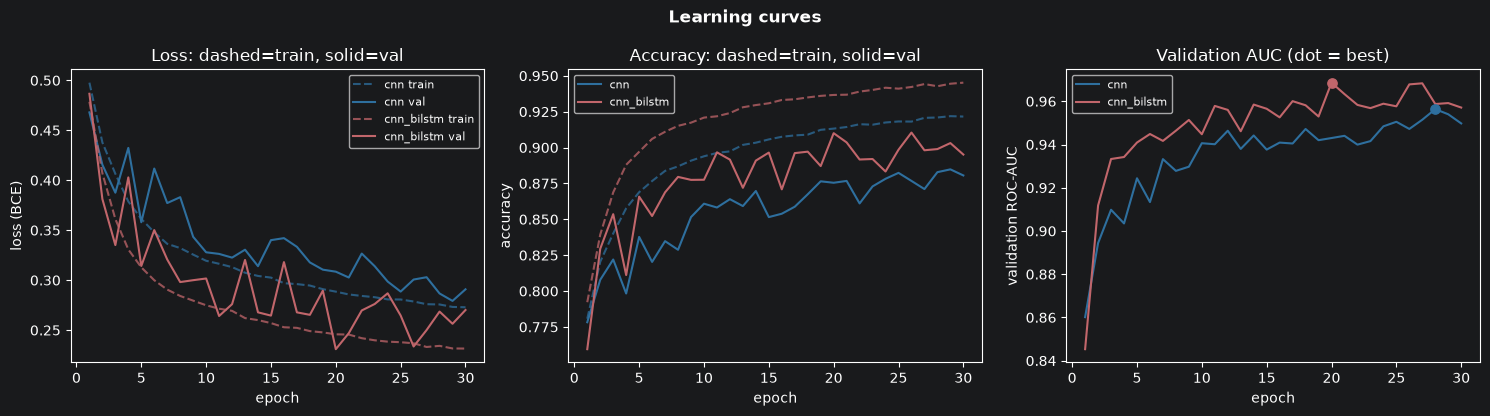

In [20]:
# Retrieve the training history
histories = {"cnn": run_baseline["history"], "cnn_bilstm": run_hybrid["history"]}

# Show graphs for loss, accuracy, and validaiton AUC
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for (label, h), c in zip(histories.items(), ("#2E6F9E", "#C1666B")):
    axes[0].plot(h["epoch"], h["train_loss"], "--", color=c, alpha=0.75, label=f"{label} train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=c, label=f"{label} val")
    axes[1].plot(h["epoch"], h["train_acc"], "--", color=c, alpha=0.75)
    axes[1].plot(h["epoch"], h["val_acc"], "-", color=c, label=label)
    axes[2].plot(h["epoch"], h["val_auc"], "-", color=c, label=label)
    i = int(np.argmax(h["val_auc"]))
    axes[2].scatter([h["epoch"][i]], [h["val_auc"][i]], color=c, zorder=5, s=45)
axes[0].set(xlabel="epoch", ylabel="loss (BCE)", title="Loss: dashed=train, solid=val")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy: dashed=train, solid=val")
axes[2].set(xlabel="epoch", ylabel="validation ROC-AUC", title="Validation AUC (dot = best)")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Learning curves", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 2: Hyperparameter Tuning

### 2.1 Tuning Configuration

In [21]:
# Define the seed
rng = np.random.default_rng(42)

# Set the sampled dataset for hyperparameter tuning
SEARCH_TRAIN_N, SEARCH_VAL_N = 30_000, 8_192
tr_sub = np.sort(rng.choice(len(ytr), SEARCH_TRAIN_N, replace=False))
va_sub = np.sort(rng.choice(len(yva), SEARCH_VAL_N, replace=False))

# Retrieve the image data and labels
xtr_s, ytr_s = np.ascontiguousarray(xtr[tr_sub]), ytr[tr_sub]
xva_s, yva_s = np.ascontiguousarray(xva[va_sub]), yva[va_sub]

# Randomly select hyperparameters for tuning
def sample_params(space, rng):
    out = {}
    for key, dist in space.items():                                     # Loop through each hyperparameter
        if dist[0] == "log":                                            # Log-sampling values
            out[key] = float(np.exp(rng.uniform(np.log(dist[1]),        # Select a random value
                                                np.log(dist[2]))))
        elif dist[0] == "uniform":                                      # Values within a range
            out[key] = float(rng.uniform(dist[1], dist[2]))             # Select a random value
        else:
            out[key] = dist[1][int(rng.integers(len(dist[1])))]         # Select a random choice
    return out

# Run a trial with a hyperparameter configuration
def run_trial(key, params, tag):
    model_kwargs = {k: v for k, v in params.items() if k in MODEL_KEYS}                     # Get parameters for model architecture
    train_kwargs = {k: v for k, v in params.items() if k not in MODEL_KEYS}                 # Get parameters for training
    t0 = time.time()                                                                        # Set the starting time
    torch.manual_seed(42)                                                                   # Set a seed
    model = MODELS[key]["cls"](**model_kwargs)                                              # Create a new model
    rec = train(model, tag, (xtr_s, ytr_s), (xva_s, yva_s),                                 # Train the model
                epochs=SEARCH_EPOCHS, verbose=False, **train_kwargs)
    return {"model": key, "params": params, "seconds": time.time() - t0, **rec["best"]}     # Return trial result

### 2.2 Search Space

In [22]:
# Settings for hyperparameter search
N_TRIALS      = 20                          # 20 different configurations
SEARCH_EPOCHS = 6                           # 6 epochs to be trained

# Model architecture
MODELS = {
    "cnn":  {"label": "CNN",                # Model name
             "cls": BaselineCNN,            # Model class
             "model": model_baseline,       # Baseline model created
             "run": run_baseline},          # Results from baseline

    "cnn_bilstm": {"label": "CNN-BiLSTM",   # Model name
                   "cls": CNNBiLSTM,        # Model class
                   "model": model_hybrid,   # Baseline hybrid model
                   "run": run_hybrid},      # Results from hybrid
}

# Hyperparameters to tune model architecture
MODEL_KEYS = {"widths", "dropout", "block_dropout", "head", "fc_dim", "hidden", "num_layers", "grid"}

# Search space for hyperparameter tuning
SPACES = {
    "cnn": {
        "lr":              ("log", 1e-4, 3e-3),
        "weight_decay":    ("log", 1e-6, 1e-2),
        "dropout":         ("uniform", 0.10, 0.50),
        "block_dropout":   ("choice", [0.0, 0.05, 0.10]),
        "head":            ("choice", ["gap", "centre", "both"]),
        "fc_dim":          ("choice", [128, 256]),
        "label_smoothing": ("choice", [0.0, 0.05, 0.10]),
        "aug_hed_sigma":   ("choice", [0.0, 0.03, 0.05, 0.10]),
        "batch_size":      ("choice", [128, 256]),
    },
    "cnn_bilstm": {
        "lr":              ("log", 1e-4, 3e-3),
        "weight_decay":    ("log", 1e-6, 1e-2),
        "dropout":         ("uniform", 0.10, 0.50),
        "block_dropout":   ("choice", [0.0, 0.05, 0.10]),
        "head":            ("choice", ["attn", "centre", "both"]),
        "hidden":          ("choice", [128, 192, 256]),
        "num_layers":      ("choice", [1, 2]),
        "fc_dim":          ("choice", [128, 256]),
        "label_smoothing": ("choice", [0.0, 0.05, 0.10]),
        "aug_hed_sigma":   ("choice", [0.0, 0.03, 0.05, 0.10]),
        "batch_size":      ("choice", [128, 256]),
    },
}

### 2.3 Random search

In [23]:
# Store results from all trials and search time
random_trials, search_time = {}, {}

# Loop through each hyperparameter
for key in MODELS:
    rng = np.random.default_rng(42)                         # Set a seed
    trials, t_start = [], time.time()                       # Record start time
    for i in range(1, N_TRIALS + 1):                        # Run 20 trials
        rec = run_trial(key,                                # Perform training
                        sample_params(SPACES[key], rng),
                        f"{key}_rand_{i:03d}")
        trials.append(rec)                                  # Save results of each trial
    random_trials[key] = trials                             # Save results of all trials
    search_time[key] = time.time() - t_start                # Save ending time

# Show random search results in table
display(pd.DataFrame([{"model": MODELS[t["model"]]["label"], **t["params"],
                       "val_auc": t["val_auc"], "val_acc": t["val_acc"]}
                      for trials in random_trials.values() for t in trials])
        .sort_values(["model", "val_auc"], ascending=[True, False]).round(5))

,model,lr,weight_decay,dropout,block_dropout,head,fc_dim,label_smoothing,aug_hed_sigma,batch_size,val_auc,val_acc,hidden,num_layers
2,CNN,0.00089,0.00195,0.27737,0.05,gap,128,0.05,0.10,128,0.93295,0.83350,NaN,NaN
17,CNN,0.00025,0.00753,0.41150,0.00,both,256,0.05,0.05,128,0.93287,0.85608,NaN,NaN
7,CNN,0.00108,0.00002,0.43290,0.05,both,256,0.05,0.10,128,0.93218,0.84937,NaN,NaN
10,CNN,0.00097,0.00008,0.32609,0.00,both,256,0.05,0.05,256,0.93132,0.81592,NaN,NaN
4,CNN,0.00141,0.00001,0.28669,0.05,gap,256,0.00,0.05,256,0.92980,0.84229,NaN,NaN
0,CNN,0.00139,0.00006,0.44344,0.00,both,128,0.00,0.05,256,0.92900,0.85510,NaN,NaN
16,CNN,0.00034,0.00000,0.14720,0.05,both,128,0.10,0.03,256,0.92394,0.84094,NaN,NaN
11,CNN,0.00067,0.00002,0.11233,0.05,centre,256,0.00,0.03,128,0.92272,0.83875,NaN,NaN
12,CNN,0.00182,0.00001,0.12332,0.10,gap,256,0.00,0.03,256,0.91765,0.83289,NaN,NaN
13,CNN,0.00066,0.00137,0.36573,0.05,centre,128,0.10,0.03,128,0.91561,0.83374,NaN,NaN


### 2.4 Best Hyperparameter Configuration

In [26]:
# Retrieve the optimal hyperparameter that gives the highest ROC-AUC
best_cfg = {}
for key in MODELS:
    winner = max(random_trials[key], key=lambda t: t["val_auc"])
    best_cfg[key] = {"params": dict(winner["params"]), "proxy_auc": winner["val_auc"]}
    print(f"\n{MODELS[key]['label']} (best validation AUC: {winner['val_auc']:.4f})")
    for k, v in winner["params"].items():
        print(f"  {k:<16} {round(v, 6) if isinstance(v, float) else v}")


CNN (best validation AUC: 0.9329)
  lr               0.000893
  weight_decay     0.001955
  dropout          0.277366
  block_dropout    0.05
  head             gap
  fc_dim           128
  label_smoothing  0.05
  aug_hed_sigma    0.1
  batch_size       128

CNN-BiLSTM (best validation AUC: 0.9422)
  lr               0.001349
  weight_decay     0.000346
  dropout          0.321432
  block_dropout    0.0
  head             centre
  hidden           256
  num_layers       1
  fc_dim           256
  label_smoothing  0.0
  aug_hed_sigma    0.03
  batch_size       128


### 2.5 Spearman Rank Correlation

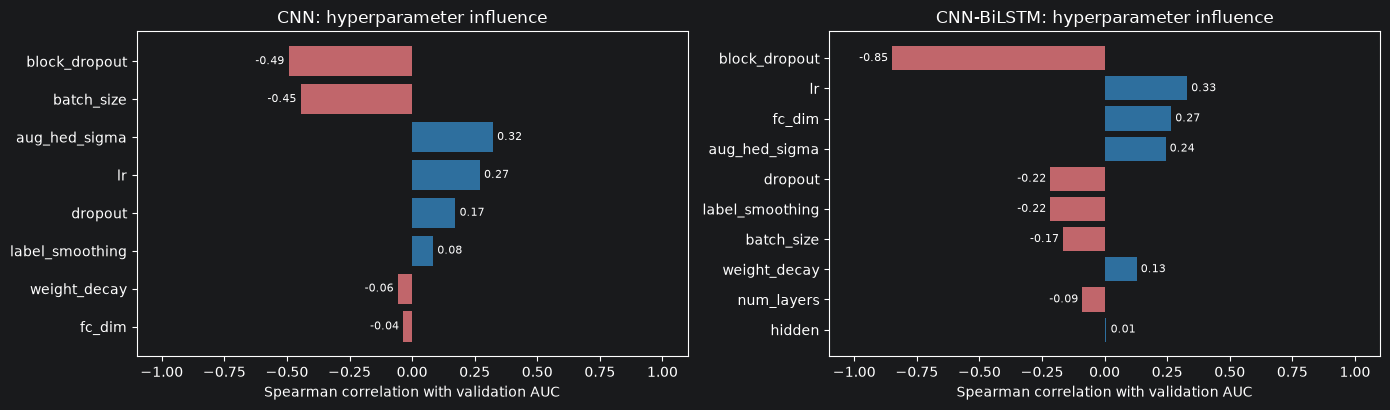

In [28]:
# The chart to display the Spearman rank correlation between hyperparameters and validation ROC-AUC
fig, axes = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 4.2))
for ax, key in zip(axes, MODELS):
    pool = pd.DataFrame([{**t["params"], "val_auc": t["val_auc"]} for t in random_trials[key]])
    cols = [c for c in pool.columns if c not in ("head", "val_auc") and pool[c].nunique() > 1]
    rho = pool[cols].astype(float).corrwith(pool["val_auc"], method="spearman")
    rho = rho.reindex(rho.abs().sort_values(ascending=False).index)
    bars = ax.barh(rho.index, rho, color=["#C1666B" if r < 0 else "#2E6F9E" for r in rho])
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xlim(-1.1, 1.1)
    ax.invert_yaxis()
    ax.set(xlabel="Spearman correlation with validation AUC",
           title=f"{MODELS[key]['label']}: hyperparameter influence")
plt.tight_layout()
plt.show()

### 2.6 Retrain Model with Optimized Hyperparameter

In [29]:
# Dictionary to store tuned models
tuned_models, tuned_runs = {}, {}

# Loop through each model
for key in MODELS:

    # Extract the best hyperparameters
    params = best_cfg[key]["params"]

    # Separate into model hyperparameters and training hyperparameters
    model_kwargs = {k: v for k, v in params.items() if k in MODEL_KEYS}
    train_kwargs = {k: v for k, v in params.items() if k not in MODEL_KEYS}

    # Set the seed
    torch.manual_seed(42)

    # Create the model with the model hyperparameters
    model = MODELS[key]["cls"](**model_kwargs)

    # Train the model with the training hyperparameters
    tuned_runs[key] = train(model, f"{key}_tuned", (xtr, ytr), (xva, yva), **train_kwargs)
    tuned_models[key] = model

# Retrieve the necessary information
rows = []
for key in MODELS:
    probs, tgt = predict(tuned_models[key], xva, yva)           # Convert score into probabilities
    m = metrics(probs, tgt)                                     # Retrieve the evaluation metrics
    rows.append({"model": MODELS[key]["label"], "accuracy": m["accuracy"], "auc": m["auc"],
                 "f1": m["f1"], "mcc": m["mcc"], "sensitivity": m["sensitivity"],
                 "specificity": m["specificity"], "nll": m["nll"]})

# Output results as a table
display(pd.DataFrame(rows).round(4))

    ep   1/30  loss 0.4686 acc 0.8013 | val acc 0.7655 auc 0.8834  63s
    ep   2/30  loss 0.3772 acc 0.8595 | val acc 0.8489 auc 0.9330  62s
    ep   3/30  loss 0.3405 acc 0.8839 | val acc 0.8466 auc 0.9298  62s
    ep   4/30  loss 0.3237 acc 0.8929 | val acc 0.8549 auc 0.9300  63s
    ep   5/30  loss 0.3092 acc 0.9020 | val acc 0.8602 auc 0.9470  63s
    ep   6/30  loss 0.3026 acc 0.9057 | val acc 0.8673 auc 0.9361  63s
    ep   7/30  loss 0.2957 acc 0.9098 | val acc 0.8664 auc 0.9370  63s
    ep   8/30  loss 0.2891 acc 0.9137 | val acc 0.8769 auc 0.9398  63s
    ep   9/30  loss 0.2831 acc 0.9173 | val acc 0.8796 auc 0.9440  63s
    ep  10/30  loss 0.2768 acc 0.9214 | val acc 0.8845 auc 0.9504  69s
    ep  11/30  loss 0.2745 acc 0.9221 | val acc 0.8943 auc 0.9558  67s
    ep  12/30  loss 0.2713 acc 0.9242 | val acc 0.8852 auc 0.9540  77s
    ep  13/30  loss 0.2690 acc 0.9248 | val acc 0.8814 auc 0.9544  74s
    ep  14/30  loss 0.2656 acc 0.9273 | val acc 0.8947 auc 0.9614  74s
    ep

,model,accuracy,auc,f1,mcc,sensitivity,specificity,nll
0,CNN,0.9064,0.9648,0.9045,0.8134,0.8877,0.9251,0.2407
1,CNN-BiLSTM,0.8737,0.9694,0.8588,0.7645,0.7686,0.9787,0.3007


## Step 3: Model Evaluation

### 3.1 Youden Threshold

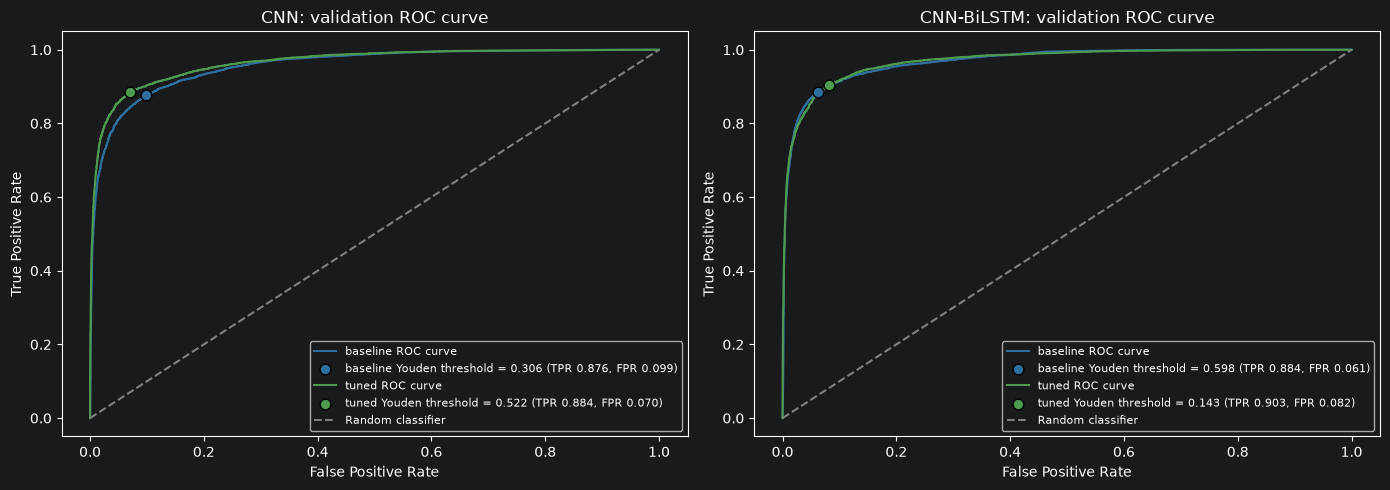

In [30]:
# Calculate the Youden threshold for each model
thresholds = {}
fig, axes = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 5))
for ax, key in zip(axes, MODELS):
    for stage, model, name, c in (("baseline", MODELS[key]["model"], key, "#2E6F9E"),
                                  ("tuned", tuned_models[key], f"{key}_tuned", "#4E9A51")):
        probs_val, tgt = predict(model, xva, yva)                                       # Validation probabilities
        fpr, tpr, thr = roc_curve(tgt, probs_val)                                       # ROC curve
        i = int(np.argmax(tpr - fpr))                                                   # Youden point
        thresholds[name] = float(thr[i])                                                # Store threshold
        ax.plot(fpr, tpr, color=c, label=f"{stage} ROC curve")                          # Plot the ROC curve
        ax.scatter(fpr[i], tpr[i], s=60, zorder=5, color=c, edgecolor="black",
                   label=f"{stage} Youden threshold = {thr[i]:.3f} (TPR {tpr[i]:.3f}, FPR {fpr[i]:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Random classifier")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
           title=f"{MODELS[key]['label']}: validation ROC curve")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.2 Comparison between Baseline Runs and Optimized Models

#### 3.2.1 Learning Curves of Optimized Models

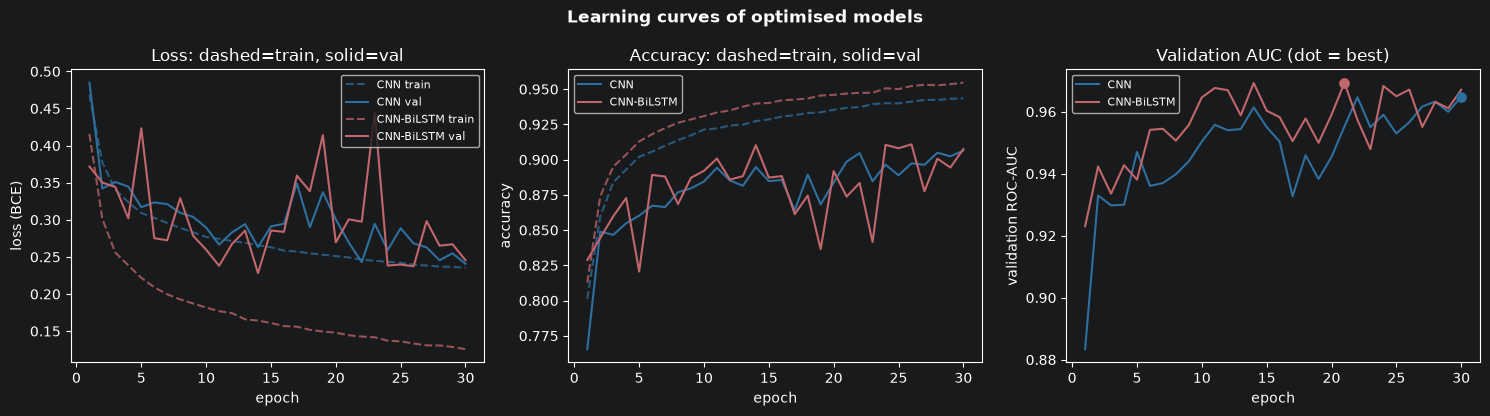

In [31]:
# Retrieve the training history of the optimized models
histories = {MODELS[key]["label"]: tuned_runs[key]["history"] for key in MODELS}

# Show graphs for loss, accuracy, and validation AUC
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for (label, h), c in zip(histories.items(), ("#2E6F9E", "#C1666B")):
    axes[0].plot(h["epoch"], h["train_loss"], "--", color=c, alpha=0.75, label=f"{label} train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=c, label=f"{label} val")
    axes[1].plot(h["epoch"], h["train_acc"], "--", color=c, alpha=0.75)
    axes[1].plot(h["epoch"], h["val_acc"], "-", color=c, label=label)
    axes[2].plot(h["epoch"], h["val_auc"], "-", color=c, label=label)
    i = int(np.argmax(h["val_auc"]))
    axes[2].scatter([h["epoch"][i]], [h["val_auc"][i]], color=c, zorder=5, s=45)
axes[0].set(xlabel="epoch", ylabel="loss (BCE)", title="Loss: dashed=train, solid=val")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy: dashed=train, solid=val")
axes[2].set(xlabel="epoch", ylabel="validation ROC-AUC", title="Validation AUC (dot = best)")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Learning curves of optimised models", fontweight="bold")
plt.tight_layout()
plt.show()

#### 3.2.2 Performance Metrics of All Models

In [42]:
# All four models, evaluated on the VALIDATION set at their own Youden threshold
candidates = {}
for key in MODELS:
    candidates[key] = {"label": f"{MODELS[key]['label']} (baseline)", "model": MODELS[key]["model"].eval()}
    candidates[f"{key}_tuned"] = {"label": f"{MODELS[key]['label']} (optimised)", "model": tuned_models[key].eval()}

rows = []
for name, entry in candidates.items():
    probs, tgt = predict(entry["model"], xva, yva)                                      # Validation probabilities
    m = metrics(probs, tgt, threshold=thresholds[name])                                 # Metrics at Youden threshold
    rows.append({"key": name, "model": entry["label"], "threshold": thresholds[name],
                 "accuracy": m["accuracy"], "auc": m["auc"], "f1": m["f1"], "mcc": m["mcc"],
                 "sensitivity": m["sensitivity"], "specificity": m["specificity"], "nll": m["nll"],
                 "parameters": sum(p.numel() for p in entry["model"].parameters())})    # Model size
val_df = pd.DataFrame(rows).set_index("key")

# Output results as a table
display(val_df.round(4))

,model,threshold,accuracy,auc,f1,mcc,sensitivity,specificity,nll,parameters
key,,,,,,,,,,
cnn,CNN (baseline),0.3058,0.8887,0.9564,0.8872,0.7776,0.8761,0.9013,0.2867,1206497
cnn_tuned,CNN (optimised),0.5219,0.9070,0.9648,0.9047,0.8148,0.8840,0.9299,0.2407,1206497
cnn_bilstm,CNN-BiLSTM (baseline),0.5979,0.9113,0.9686,0.9088,0.8238,0.8840,0.9385,0.2309,2291937
cnn_bilstm_tuned,CNN-BiLSTM (optimised),0.1433,0.9108,0.9694,0.9100,0.8216,0.9033,0.9182,0.3007,2357985


### 3.3 Champion Model Selection

In [43]:
tied = val_df[val_df["auc"] >= val_df["auc"].max() - 0.001]         # Models with ROC-AUC within 0.001 are tied
BEST_KEY = tied["nll"].idxmin()                                     # The tie is broken using negative log-likelihood
champion = candidates[BEST_KEY]["model"]                            # Retrieve the details of the champion model
champion_label = candidates[BEST_KEY]["label"]
thr_champ = thresholds[BEST_KEY]

### 3.4 Fit Model on Test Set

In [44]:
xte = np.load(PROCESSED / "test_full_x.npy", mmap_mode="r")                     # Load the test set
yte = np.load(PROCESSED / "test_full_y.npy").astype(np.float32).reshape(-1)
test_probs, y_test = predict(champion, xte, yte)                                # Predict using the champion model
m_test = metrics(test_probs, y_test, threshold=thr_champ)                       # Retrieve metrics
display(pd.DataFrame([{"model": champion_label, "threshold": thr_champ,
                       **{k: m_test[k] for k in ("accuracy", "auc", "sensitivity", "specificity",
                                                  "precision", "f1", "mcc", "nll", "brier")}}]).round(4))

,model,threshold,accuracy,auc,sensitivity,specificity,precision,f1,mcc,nll,brier
0,CNN-BiLSTM (baseline),0.5979,0.8764,0.9541,0.8091,0.9437,0.9349,0.8675,0.7598,0.2828,0.0855


### 3.5 Final Evaluation of Champion Model on Test Set

#### 3.5.1 Confusion Matrix

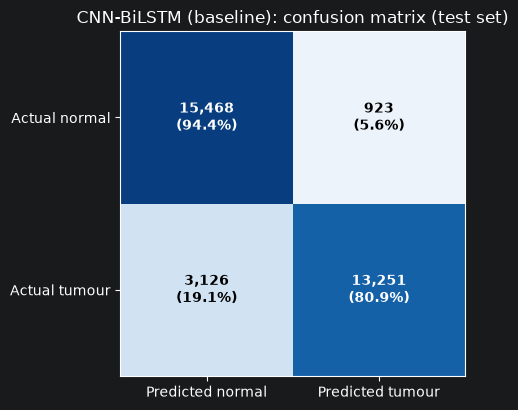

In [46]:
cm = np.array([[m_test["tn"], m_test["fp"]], [m_test["fn"], m_test["tp"]]])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.1%})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontweight="bold")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Predicted normal", "Predicted tumour"],
       yticklabels=["Actual normal", "Actual tumour"],
       title=f"{champion_label}: confusion matrix (test set)")
ax.grid(False)
plt.tight_layout()
plt.show()

#### 3.5.2 ROC Curve

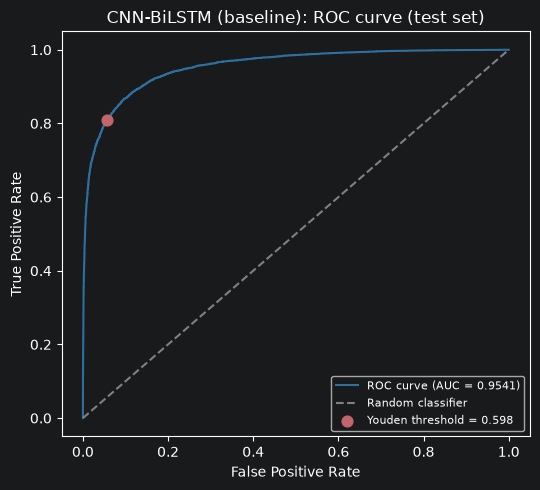

In [47]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#2E6F9E", label=f"ROC curve (AUC = {m_test['auc']:.4f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random classifier")
ax.scatter(1 - m_test["specificity"], m_test["sensitivity"], s=60, zorder=5, color="#C1666B",
           label=f"Youden threshold = {thr_champ:.3f}")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title=f"{champion_label}: ROC curve (test set)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

#### 3.5.3 Calibration Curve

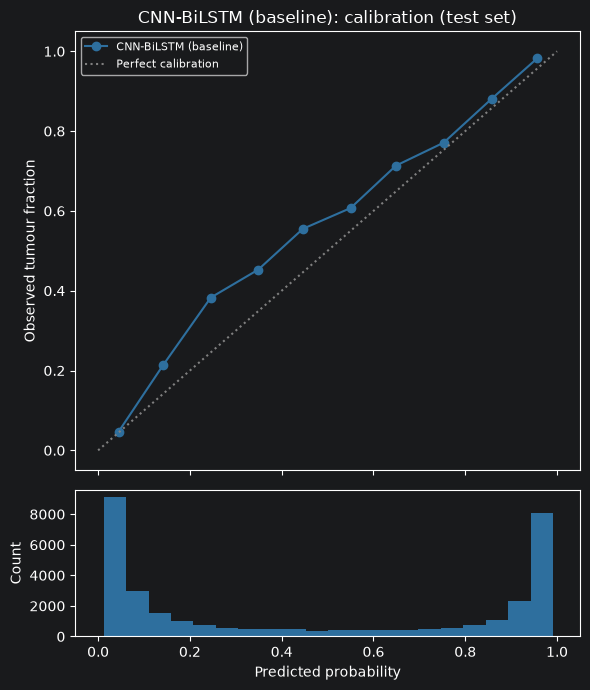

NLL 0.2828   Brier score 0.0855


In [41]:
frac_pos, mean_pred = calibration_curve(y_test, test_probs, n_bins=10)
fig, (ax, ax_hist) = plt.subplots(2, 1, figsize=(6, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(mean_pred, frac_pos, "o-", color="#2E6F9E", label=champion_label)
ax.plot([0, 1], [0, 1], ":", color="grey", label="Perfect calibration")
ax.set(ylabel="Observed tumour fraction", title=f"{champion_label}: calibration (test set)")
ax.legend(fontsize=8)
ax_hist.hist(test_probs, bins=20, color="#2E6F9E")
ax_hist.set(xlabel="Predicted probability", ylabel="Count")
plt.tight_layout()
plt.show()